# Olist Supply Chain Analysis
# Exploratory Data Analysis (EDA)

## Main Objectives
- Understand the structure and quality of the dataset.
- Identify missing values, duplicates, and data inconsistencies.
- Analyze sales and product performance.
- Explore customer purchasing behavior.
- Understand payment methods and transaction patterns.
- Evaluate delivery and logistics performance.
- Identify geographical business patterns.
- Analyze trends over time.
- Generate actionable business insights.

### Dataset
The dataset contains 8 related tables:
Orders, Order_Items, Payments, Reviews,
Products, Sellers, Translation, and Customers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "olist_Cleaned_Dataset (4).xlsx"


sheets = pd.read_excel(file_path, sheet_name=None)

for name, df in sheets.items():
    print(f"{name}: {df.shape[0]:,} Rows × {df.shape[1]} Columns")
print("All datasets loaded successfully!")

Orders: 8,002 Rows × 8 Columns
Order_Items: 8,942 Rows × 9 Columns
Payments: 8,406 Rows × 5 Columns
Reviews: 7,986 Rows × 7 Columns
Products: 5,622 Rows × 9 Columns
Sellers: 1,491 Rows × 4 Columns
Translation: 71 Rows × 2 Columns
Customers: 8,002 Rows × 5 Columns
All datasets loaded successfully!


In [2]:
quality = pd.DataFrame([
    {
        "Table": name,
        "Rows": len(df),
        "Missing cells": int(df.isna().sum().sum()),
        "Duplicate full rows": int(df.duplicated().sum()),
    }
    for name, df in sheets.items()
])

print(quality)

         Table  Rows  Missing cells  Duplicate full rows
0       Orders  8002            422                    0
1  Order_Items  8942              0                    0
2     Payments  8406              0                    0
3      Reviews  7986              0                    0
4     Products  5622              0                    0
5      Sellers  1491              0                    0
6  Translation    71              0                    0
7    Customers  8002              0                    0


In [3]:
primary_keys = {
    "Orders": ["order_id"],
    "Order_Items": ["order_id", "order_item_id"],
    "Payments": ["order_id", "payment_sequential"],
    "Reviews": ["review_id", "order_id"],
    "Customers": ["customer_id"],
    "Products": ["product_id"],
    "Sellers": ["seller_id"],
    "Translation": ["product_category_name"],
}

key_check = []

for table, keys in primary_keys.items():
    df = sheets[table]

    key_check.append({
        "Table": table,
        "Key": " + ".join(keys),
        "Rows with null key": int(df[keys].isna().any(axis=1).sum()),
        "Duplicate key rows": int(df.duplicated(subset=keys).sum()),
    })

print(pd.DataFrame(key_check))

         Table                            Key  Rows with null key  \
0       Orders                       order_id                   0   
1  Order_Items       order_id + order_item_id                   0   
2     Payments  order_id + payment_sequential                   0   
3      Reviews           review_id + order_id                   0   
4    Customers                    customer_id                   0   
5     Products                     product_id                   0   
6      Sellers                      seller_id                   0   
7  Translation          product_category_name                   0   

   Duplicate key rows  
0                   0  
1                   0  
2                   0  
3                   0  
4                   0  
5                   0  
6                   0  
7                   0  


In [4]:
def count_orphans(child_table, child_key, parent_table, parent_key):
    child_values = sheets[child_table][child_key].dropna().astype("string")
    parent_values = set(
        sheets[parent_table][parent_key].dropna().astype("string")
    )

    return int((~child_values.isin(parent_values)).sum())


relationships = [
    ("Orders", "customer_id", "Customers", "customer_id"),
    ("Order_Items", "order_id", "Orders", "order_id"),
    ("Order_Items", "product_id", "Products", "product_id"),
    ("Order_Items", "seller_id", "Sellers", "seller_id"),
    ("Payments", "order_id", "Orders", "order_id"),
    ("Reviews", "order_id", "Orders", "order_id"),
]

for child, child_key, parent, parent_key in relationships:
    orphan_count = count_orphans(child, child_key, parent, parent_key)
    print(f"{child}.{child_key} → {parent}.{parent_key}: {orphan_count} orphan rows")

Orders.customer_id → Customers.customer_id: 0 orphan rows
Order_Items.order_id → Orders.order_id: 0 orphan rows
Order_Items.product_id → Products.product_id: 0 orphan rows
Order_Items.seller_id → Sellers.seller_id: 0 orphan rows
Payments.order_id → Orders.order_id: 0 orphan rows
Reviews.order_id → Orders.order_id: 0 orphan rows


In [5]:
reviews = sheets["Reviews"]
products = sheets["Products"]

for column in ["review_comment_title", "review_comment_message"]:
    if column in reviews.columns:
        count = (reviews[column] == "No Comment").sum()
        print(f"{column} = No Comment: {count:,}")

unknown_categories = (
    products["product_category_name"] == "Unknown"
).sum()

print(f"Product category = Unknown: {unknown_categories:,}")

review_comment_title = No Comment: 7,034
review_comment_message = No Comment: 4,658
Product category = Unknown: 92


In [6]:
date_columns = {
    "Orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    "Order_Items": ["shipping_limit_date"],
    "Reviews": [
        "review_creation_date",
        "review_answer_timestamp",
    ],
}

for table, columns in date_columns.items():
    for column in columns:
        if column in sheets[table].columns:
            sheets[table][column] = pd.to_datetime(
                sheets[table][column],
                errors="coerce"
            )

date_summary = []

for table, columns in date_columns.items():
    for column in columns:
        if column in sheets[table].columns:
            dates = sheets[table][column]

            date_summary.append({
                "Table": table,
                "Column": column,
                "Earliest": dates.min(),
                "Latest": dates.max(),
                "Missing": int(dates.isna().sum()),
            })

print(pd.DataFrame(date_summary))

         Table                         Column            Earliest  \
0       Orders       order_purchase_timestamp 2017-01-05 12:11:23   
1       Orders              order_approved_at 2017-01-07 03:35:21   
2       Orders   order_delivered_carrier_date 2017-01-09 16:55:33   
3       Orders  order_delivered_customer_date 2017-01-13 12:27:45   
4       Orders  order_estimated_delivery_date 2017-02-07 00:00:00   
5  Order_Items            shipping_limit_date 2017-01-09 12:11:23   
6      Reviews           review_creation_date 2017-01-14 00:00:00   
7      Reviews        review_answer_timestamp 2017-01-16 00:02:47   

               Latest  Missing  
0 2018-08-29 09:14:11        0  
1 2018-08-29 09:25:12       16  
2 2018-08-29 19:02:00      149  
3 2018-09-25 00:47:25      257  
4 2018-10-17 00:00:00        0  
5 2018-09-06 09:15:09        0  
6 2018-08-31 00:00:00        0  
7 2018-10-22 03:33:14        0  


In [7]:
for table in ["Orders", "Order_Items", "Payments", "Reviews", "Products"]:
    print(f"\n{table}")
    print(sheets[table].describe(include="all").T)


Orders
                              count unique                               top  \
order_id                       8002   8002  6acecf438369055d9243e121045cca74   
customer_id                    8002   8002  42d857e22f61f10476f0cda1aacc018a   
order_status                   8002      6                         delivered   
order_purchase_timestamp       8002    NaN                               NaN   
order_approved_at              7986    NaN                               NaN   
order_delivered_carrier_date   7853    NaN                               NaN   
order_delivered_customer_date  7745    NaN                               NaN   
order_estimated_delivery_date  8002    NaN                               NaN   

                               freq                        mean  \
order_id                          1                         NaN   
customer_id                       1                         NaN   
order_status                   7746                         NaN   
ord

,Items,Unique_orders,Item_price_total
product_category_name_english,,,
watches_gifts,537,509,105564.80
health_beauty,740,677,94052.42
bed_bath_table,878,760,81912.23
sports_leisure,693,620,80025.42
computers_accessories,659,588,71308.69
furniture_decor,696,544,63491.70
auto,365,337,48033.41
cool_stuff,279,273,46152.94
housewares,509,440,45072.39


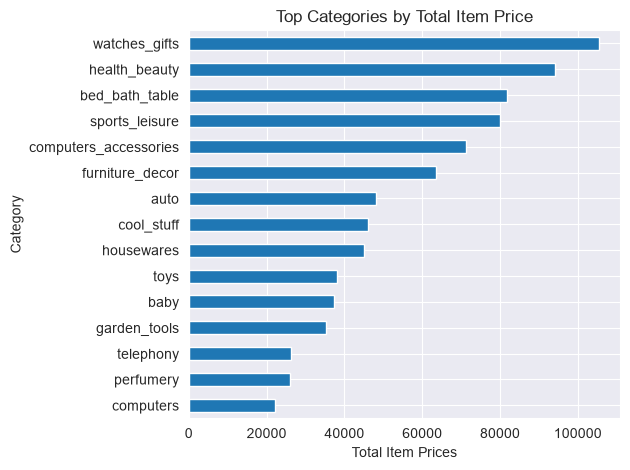

In [8]:
items = sheets["Order_Items"].copy()
products = sheets["Products"].copy()
translation = sheets["Translation"].copy()

products_translated = products.merge(
    translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

items_products = items.merge(
    products_translated,
    on="product_id",
    how="left",
    validate="many_to_one"
)

category_column = "product_category_name_english"

items_products[category_column] = (
    items_products[category_column]
    .fillna("Unknown / untranslated")
)

category_summary = (
    items_products
    .groupby(category_column, dropna=False)
    .agg(
        Items=("order_item_id", "size"),
        Unique_orders=("order_id", "nunique"),
        Item_price_total=("price", "sum"),
    )
    .sort_values("Item_price_total", ascending=False)
)

display(category_summary.head(15))

category_summary["Item_price_total"].head(15).sort_values().plot(
    kind="barh"
)
plt.title("Top Categories by Total Item Price")
plt.xlabel("Total Item Prices")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

,Payment_rows,Unique_orders,Payment_value_total
payment_type,,,
credit_card,6162,6139,998943.13
boleto,1609,1609,217873.34
voucher,514,331,30170.16
debit_card,121,121,15220.45


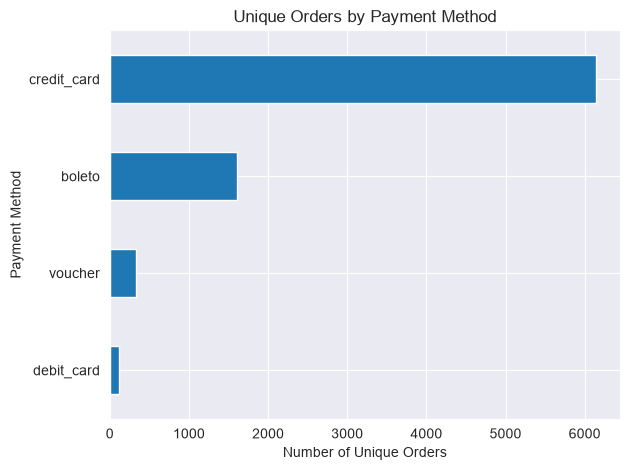

In [9]:
payments = sheets["Payments"].copy()

payment_summary = (
    payments
    .groupby("payment_type", dropna=False)
    .agg(
        Payment_rows=("order_id", "size"),
        Unique_orders=("order_id", "nunique"),
        Payment_value_total=("payment_value", "sum"),
    )
    .sort_values("Payment_value_total", ascending=False)
)

display(payment_summary)

payment_summary["Unique_orders"].sort_values().plot(kind="barh")
plt.title("Unique Orders by Payment Method")
plt.xlabel("Number of Unique Orders")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

Orders with more than one review record: 49


,Orders
Latest review score,
1,911
2,246
3,676
4,1537
5,4566


Average latest review score: 4.08


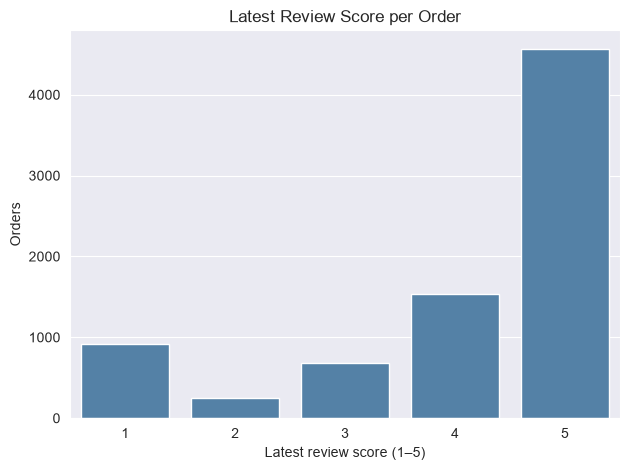

In [10]:
reviews = sheets["Reviews"].copy()
review_counts = reviews.groupby("order_id")["review_id"].size()
print(f"Orders with more than one review record: {int((review_counts > 1).sum())}")

# Use each order's latest review so every plotted score stays on the 1–5 scale.
latest_reviews = reviews.sort_values("review_creation_date").drop_duplicates("order_id", keep="last")
score_counts = latest_reviews["review_score"].value_counts().sort_index()
display(score_counts.rename_axis("Latest review score").to_frame("Orders"))
print("Average latest review score:", round(latest_reviews["review_score"].mean(), 2))
sns.countplot(data=latest_reviews, x="review_score", color="steelblue")
plt.title("Latest Review Score per Order")
plt.xlabel("Latest review score (1–5)")
plt.ylabel("Orders")
plt.tight_layout()
plt.show()

Number of Delivered Orders: 7746
Orders Eligible for Delay Calculation: 7745
Delay Rate Among Eligible Orders: 8.64 %


,count,mean,std,min,25%,50%,75%,max
delivery_days,7745.0,12.659193,9.659463,0.984375,6.794213,10.206111,15.905799,187.203449
delay_days,7745.0,-11.029802,10.198675,-146.016123,-16.212199,-11.523507,-6.310069,152.683171


Longest recorded purchase-to-delivery duration: 187.20 days


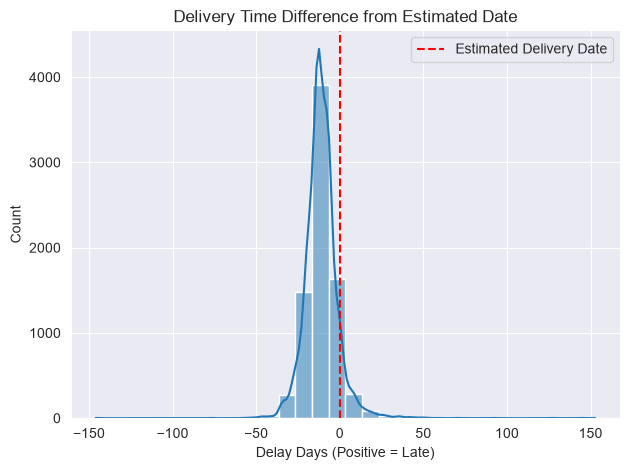

In [11]:
delivery = sheets["Orders"].copy()
delivery = delivery.loc[delivery["order_status"].eq("delivered")].copy()
delivery["delivery_days"] = (delivery["order_delivered_customer_date"] - delivery["order_purchase_timestamp"]).dt.total_seconds() / 86400
delivery["delay_days"] = (delivery["order_delivered_customer_date"] - delivery["order_estimated_delivery_date"]).dt.total_seconds() / 86400
valid_delivery = delivery.dropna(subset=["delivery_days", "delay_days"]).copy()
valid_delivery["late"] = valid_delivery["delay_days"] > 0
print("Number of Delivered Orders:", len(delivery))
print("Orders Eligible for Delay Calculation:", len(valid_delivery))
print("Delay Rate Among Eligible Orders:", round(valid_delivery["late"].mean() * 100, 2), "%")
display(valid_delivery[["delivery_days", "delay_days"]].describe().T)
print(f"Longest recorded purchase-to-delivery duration: {valid_delivery['delivery_days'].max():.2f} days")
sns.histplot(valid_delivery["delay_days"], bins=30, kde=True)
plt.axvline(0, color="red", linestyle="--", label="Estimated Delivery Date")
plt.title("Delivery Time Difference from Estimated Date")
plt.xlabel("Delay Days (Positive = Late)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** 8.64% of 7,745 eligible delivered orders were late. Median delivery time was 10.21 days; investigate the extreme 187-day delivery.

,Unique orders
customer_state,
SP,3369
RJ,993
MG,923
RS,450
PR,428
SC,286
BA,282
DF,181
ES,161


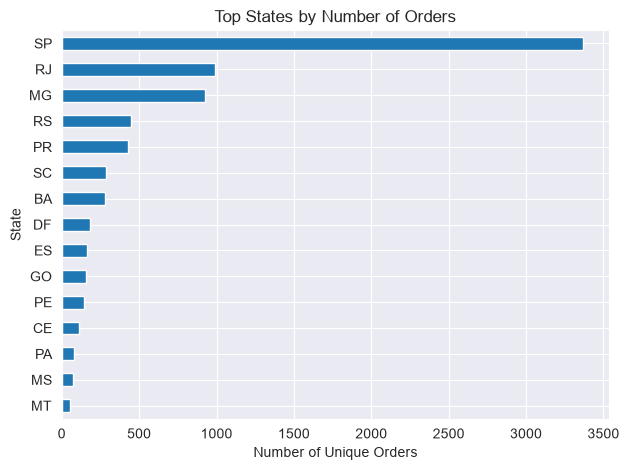

,eligible_orders,late_orders,late_rate,median_delay_days
customer_state,,,,
AL,31,7,0.226,-13.344
MA,55,11,0.200,-8.085
PE,131,23,0.176,-12.356
PA,77,12,0.156,-13.337
ES,159,24,0.151,-9.286
CE,108,16,0.148,-12.118
RJ,941,136,0.145,-12.216
PI,42,6,0.143,-13.174
AP,8,1,0.125,-18.563


In [12]:
orders_customers = sheets["Orders"].merge(
    sheets["Customers"][["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

state_orders = (
    orders_customers
    .groupby("customer_state", dropna=False)["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

display(state_orders.head(15).to_frame("Unique orders"))

state_orders.head(15).sort_values().plot(kind="barh")
plt.title("Top States by Number of Orders")
plt.xlabel("Number of Unique Orders")
plt.ylabel("State")
plt.tight_layout()
plt.show()

# Order-level late-delivery rate by customer state
state_delivery = valid_delivery.merge(
    sheets["Customers"][["customer_id", "customer_state"]],
    on="customer_id", how="left", validate="many_to_one"
)
late_by_customer_state = (
    state_delivery.dropna(subset=["customer_state"])
    .groupby("customer_state")
    .agg(eligible_orders=("order_id", "nunique"), late_orders=("late", "sum"),
         late_rate=("late", "mean"), median_delay_days=("delay_days", "median"))
    .sort_values("late_rate", ascending=False)
)
display(late_by_customer_state.round(3))


**Interpretation:** Compare every state’s late rate with its eligible order count. RJ is about 14.5% across 941 eligible orders; this is descriptive, not causal.

In [13]:
order_items = sheets["Order_Items"].copy()

for column in ["price_outlier", "freight_outlier"]:
    if column in order_items.columns:
        print(f"\n{column}")
        display(
            order_items[column]
            .value_counts(dropna=False)
            .rename_axis(column)
            .to_frame("Rows")
        )

for column in ["price", "freight_value"]:
    print(f"\n{column}")
    display(
        order_items[column].describe(
            percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
        )
    )


price_outlier


,Rows
price_outlier,
False,8291
True,651



freight_outlier


,Rows
freight_outlier,
False,7983
True,959



price


count    8942.00000
mean      119.53334
std       180.43619
min         3.06000
50%        71.90000
75%       133.15000
90%       226.95000
95%       349.00000
99%       899.00000
max      4590.00000
Name: price, dtype: float64


freight_value


count    8942.000000
mean       19.691457
std        15.577662
min         0.000000
50%        16.160000
75%        20.850000
90%        32.820000
95%        44.107500
99%        79.375800
max       338.300000
Name: freight_value, dtype: float64

In [14]:
items_by_order = (
    sheets["Order_Items"]
    .groupby("order_id", as_index=False)
    .agg(
        Item_price_total=("price", "sum"),
        Freight_total=("freight_value", "sum"),
        Item_count=("order_item_id", "size"),
    )
)

payments_by_order = (
    sheets["Payments"]
    .groupby("order_id", as_index=False)
    .agg(
        Payment_total=("payment_value", "sum"),
        Payment_records=("payment_sequential", "size"),
    )
)

order_level = sheets["Orders"].merge(
    items_by_order,
    on="order_id",
    how="left",
    validate="one_to_one"
).merge(
    payments_by_order,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Original Orders Rows:", len(sheets["Orders"]))
print("Table Rows After Aggregation and Joining:", len(order_level))

print(order_level.head())

Original Orders Rows: 8002
Table Rows After Aggregation and Joining: 8002
                           order_id                       customer_id  \
0  6acecf438369055d9243e121045cca74  42d857e22f61f10476f0cda1aacc018a   
1  1b694ef5b28d3e949a4f0ffeb2c9fcd6  cba12036a88407a37770dc8ab725de77   
2  2f9d791088532b218b41f892cc16073b  937bb74713a47912471275b234236764   
3  d82cef48824870df9946d57e827ed727  500bbe66867d0f0bdb3531af1e052b4b   
4  9021fdebb45ac827a6033d6969d5c2e3  7fdeb74955a334e7a83f3bb365c07727   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-01-05 12:11:23 2017-01-07 03:44:07   
1    delivered      2017-01-05 13:43:17 2017-01-07 03:35:38   
2    delivered      2017-01-05 13:48:48 2017-01-07 03:35:21   
3    delivered      2017-01-05 14:33:39 2017-01-07 03:44:20   
4    delivered      2017-01-05 19:52:28 2017-01-07 03:35:30   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-01-11 16:22:53           201

## Sales Performance Analysis

This section analyzes the overall sales performance of the business.

The analysis focuses on:
- Total merchandise sales.
- Total freight value.
- Average order value.
- Monthly sales trends.

The objective is to understand the business revenue
and identify changes in sales performance over time.

,Unique orders
purchase_month,
2017-01,65
2017-02,144
2017-03,217
2017-04,194
2017-05,299
2017-06,262
2017-07,325
2017-08,350
2017-09,346


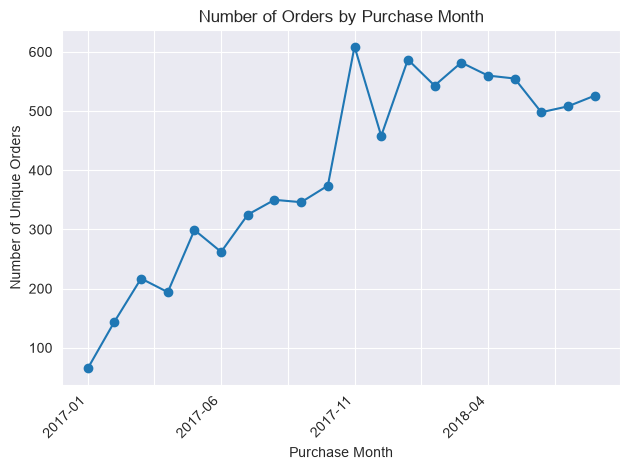

              Orders
Order status        
delivered       7746
shipped          104
unavailable       56
canceled          47
processing        29
invoiced          20


In [15]:
orders = sheets["Orders"].copy()

orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_orders = (
    orders.groupby("purchase_month")["order_id"]
    .nunique()
    .sort_index()
)

display(monthly_orders.rename("Unique orders").to_frame())

monthly_orders.plot(kind="line", marker="o")
plt.title("Number of Orders by Purchase Month")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

status_counts = orders["order_status"].value_counts(dropna=False)
print(status_counts.rename_axis("Order status").to_frame("Orders"))

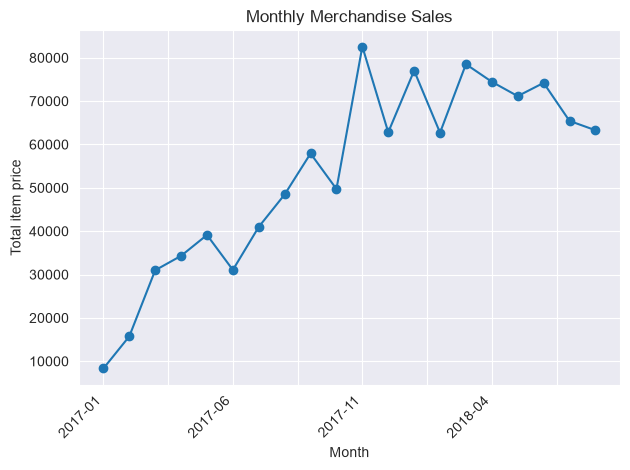

In [16]:
monthly_sales = (
    order_level.assign(
        purchase_month=order_level["order_purchase_timestamp"]
        .dt.to_period("M")
        .astype(str)
    )
    .groupby("purchase_month")["Item_price_total"]
    .sum()
    .sort_index()
)

monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Merchandise Sales")
plt.xlabel("Month")
plt.ylabel("Total item price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [17]:

total_sales = sheets["Order_Items"]["price"].sum()


total_freight = sheets["Order_Items"]["freight_value"].sum()


average_order_value = order_level["Item_price_total"].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Freight:", round(total_freight, 2))
print("Average Order Value:", round(average_order_value, 2))

Total Sales: 1068867.13
Total Freight: 176081.01
Average Order Value: 134.8


## Product Performance Analysis

This section evaluates product performance across different categories.

The analysis focuses on:
- Top-selling product categories.
- Number of items sold in each category.
- Average product price by category.

The objective is to identify the most popular
and valuable product categories.

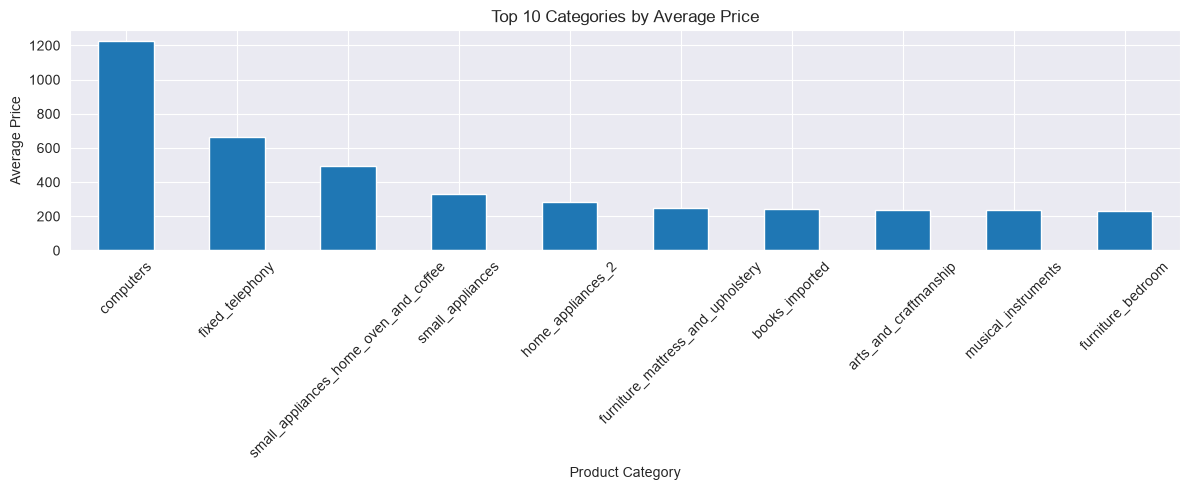

In [18]:
average_category_price = (
    items_products.groupby("product_category_name_english")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

average_category_price.plot(kind="bar", figsize=(12, 5))

plt.title("Top 10 Categories by Average Price")
plt.xlabel("Product Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

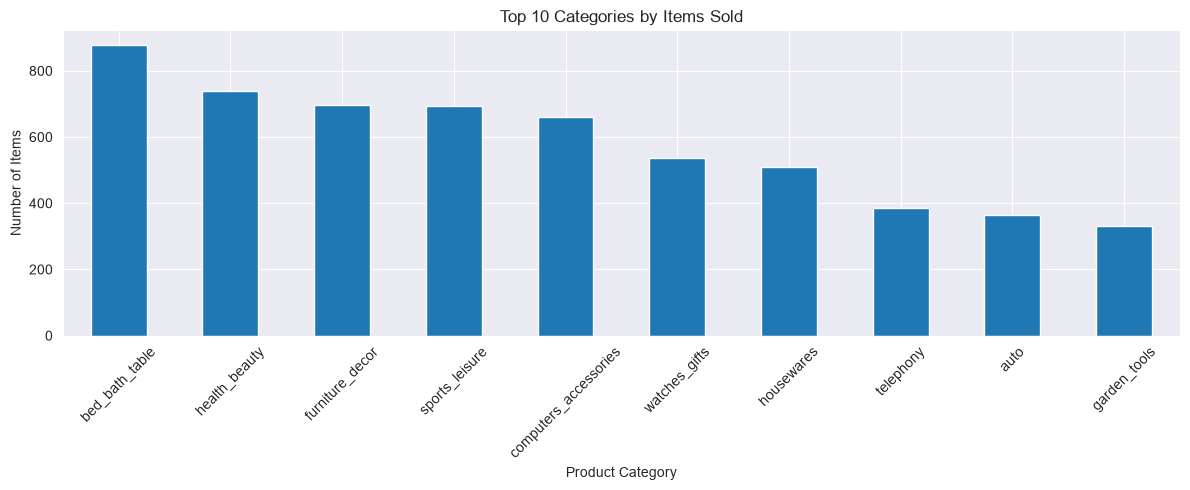

In [19]:
# Top 10 Categories by Number of Items

top_categories = (
    items_products.groupby("product_category_name_english")["order_item_id"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

top_categories.plot(kind="bar", figsize=(12, 5))

plt.title("Top 10 Categories by Items Sold")
plt.xlabel("Product Category")
plt.ylabel("Number of Items")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Customer Behavior Analysis

This section explores customer purchasing behavior.

The analysis focuses on:
- Total unique customers.
- One-time customers.
- Repeat customers.
- Customer purchasing frequency.

The objective is to understand customer retention
and identify opportunities to improve customer loyalty.

In [20]:
orders_customers = sheets["Orders"].merge(
    sheets["Customers"][["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

customer_orders = (
    orders_customers.groupby("customer_unique_id")["order_id"]
    .nunique()
)

repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()

print("Unique Customers:", len(customer_orders))
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

Unique Customers: 7979
One-Time Customers: 7956
Repeat Customers: 23


## Delivery Time and Customer Satisfaction

This section investigates the relationship between
delivery duration and customer review scores.

The objective is to understand whether longer delivery
times are associated with lower customer satisfaction.

Orders with multiple review records: 49


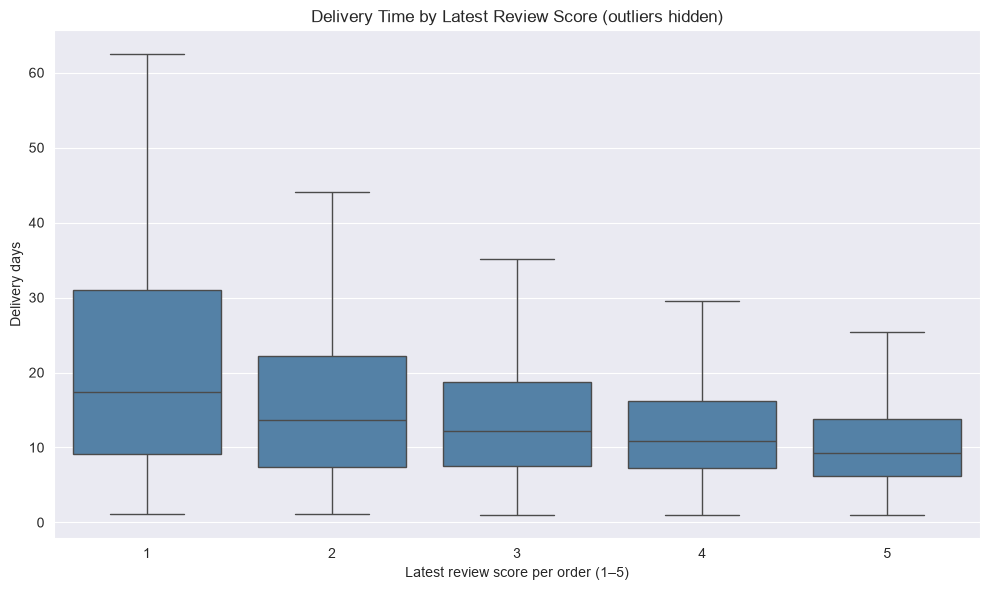

,count,median,mean
review_score,,,
1,738,17.43,21.72
2,230,13.70,16.56
3,654,12.20,14.40
4,1526,10.91,12.45
5,4538,9.21,10.75


Spearman correlation: -0.24


In [21]:
reviews = sheets["Reviews"].copy()
review_counts = reviews.groupby("order_id")["review_id"].size()
print(f"Orders with multiple review records: {int((review_counts > 1).sum())}")

# Use the latest review per order to avoid fractional mean scores.
latest_reviews = (reviews.sort_values("review_creation_date")
                 .drop_duplicates("order_id", keep="last")
                 [["order_id", "review_score"]])
delivery_reviews = sheets["Orders"].merge(
    latest_reviews, on="order_id", how="inner", validate="one_to_one")
delivery_reviews = delivery_reviews.loc[
    delivery_reviews["order_status"].eq("delivered")
].dropna(subset=["order_delivered_customer_date", "order_purchase_timestamp", "review_score"]).copy()
delivery_reviews["delivery_days"] = (
    delivery_reviews["order_delivered_customer_date"] -
    delivery_reviews["order_purchase_timestamp"]
).dt.total_seconds() / 86400
delivery_reviews = delivery_reviews.loc[delivery_reviews["delivery_days"] >= 0]
plt.figure(figsize=(10, 6))
sns.boxplot(data=delivery_reviews, x="review_score", y="delivery_days",
            color="steelblue", showfliers=False)
plt.title("Delivery Time by Latest Review Score (outliers hidden)")
plt.xlabel("Latest review score per order (1–5)")
plt.ylabel("Delivery days")
plt.tight_layout()
plt.show()
display(delivery_reviews.groupby("review_score")["delivery_days"]
        .agg(["count", "median", "mean"]).round(2))
print("Spearman correlation:",
      round(delivery_reviews[["delivery_days", "review_score"]]
            .corr(method="spearman").iloc[0, 1], 3))

**Interpretation:** This plot uses the latest review per order, so scores remain integers from 1 to 5. There are 49 orders with multiple review records; latest-review selection avoids fractional mean scores.

In [22]:
date_check = sheets["Orders"].copy()
date_check["carrier_before_purchase"] = date_check["order_delivered_carrier_date"] < date_check["order_purchase_timestamp"]
date_check["carrier_before_approval"] = date_check["order_delivered_carrier_date"] < date_check["order_approved_at"]
display(pd.DataFrame({
    "Check": ["Carrier handoff before purchase", "Carrier handoff before approval"],
    "Rows": [int(date_check["carrier_before_purchase"].fillna(False).sum()),
             int(date_check["carrier_before_approval"].fillna(False).sum())]
}))


,Check,Rows
0,Carrier handoff before purchase,16
1,Carrier handoff before approval,126


In [23]:
# Category and seller rates are item-row level; monthly rates count orders once.
item_delivery = items_products.merge(
    valid_delivery[["order_id","late","delay_days","order_purchase_timestamp"]],
    on="order_id", how="inner", validate="many_to_one")
item_delivery["purchase_month"] = item_delivery["order_purchase_timestamp"].dt.to_period("M").astype(str)
def item_delay_summary(frame, group_col):
    return (frame.dropna(subset=[group_col]).groupby(group_col)
        .agg(item_rows=("order_item_id","size"), unique_orders=("order_id","nunique"),
             late_rate=("late","mean"), median_delay_days=("delay_days","median"))
        .query("item_rows >= 20").sort_values("late_rate",ascending=False))
print("Category delay rates (item rows; at least 20 rows):")
display(item_delay_summary(item_delivery,"product_category_name_english").round(3).head(15))
print("Seller delay rates (item rows; at least 20 rows):")
display(item_delay_summary(item_delivery,"seller_id").round(3).head(15))
monthly_late = (valid_delivery.assign(
        purchase_month=valid_delivery["order_purchase_timestamp"].dt.to_period("M").astype(str))
    .groupby("purchase_month")
    .agg(eligible_orders=("order_id","nunique"), late_orders=("late","sum"),
         late_rate=("late","mean"), median_delay_days=("delay_days","median"))
    .sort_values("late_rate",ascending=False))
print("Monthly delay rates (one row per eligible order):")
display(monthly_late.round(3))


Category delay rates (item rows; at least 20 rows):


,item_rows,unique_orders,late_rate,median_delay_days
product_category_name_english,,,,
audio,20,19,0.350,-6.857
food,40,34,0.250,-9.051
art,20,20,0.200,-6.096
books_technical,21,21,0.190,-10.107
electronics,213,197,0.141,-10.331
fashion_shoes,22,21,0.136,-15.779
market_place,23,22,0.130,-11.015
baby,246,235,0.106,-11.340
furniture_living_room,38,32,0.105,-11.648


Seller delay rates (item rows; at least 20 rows):


,item_rows,unique_orders,late_rate,median_delay_days
seller_id,,,,
88460e8ebdecbfecb5f9601833981930,21,17,0.333,-9.357
4c2b230173bb36f9b240f2b8ac11786e,30,20,0.233,-7.688
8160255418d5aaa7dbdc9f4c64ebda44,35,32,0.229,-6.101
e9bc59e7b60fc3063eb2290deda4cced,22,15,0.227,-15.456
06a2c3af7b3aee5d69171b0e14f0ee87,28,27,0.214,-13.161
1da3aeb70d7989d1e6d9b0e887f97c23,27,21,0.185,-10.508
e9d99831abad74458942f21e16f33f92,22,18,0.182,-9.055
c3867b4666c7d76867627c2f7fb22e21,23,22,0.174,-8.433
8d956fec2e4337affcb520f56fd8cbfd,24,22,0.167,-8.195


Monthly delay rates (one row per eligible order):


,eligible_orders,late_orders,late_rate,median_delay_days
purchase_month,,,,
2018-03,568,119,0.210,-6.992
2018-02,529,88,0.166,-9.206
2017-11,588,84,0.143,-9.074
2018-08,510,53,0.104,-6.136
2018-05,539,53,0.098,-11.221
2017-12,439,41,0.093,-13.179
2017-04,188,16,0.085,-13.587
2017-10,359,29,0.081,-11.289
2017-03,206,15,0.073,-12.765


**Method note:** Category and seller delay rates use item rows and show unique order counts; monthly rates count each eligible order once. An order with items from multiple categories or sellers can appear in multiple item-level groups.

## Freight Cost Analysis

This section examines shipping costs across product categories.

The analysis focuses on:
- Total freight value.
- Average freight value.
- Freight cost compared with product prices.

The objective is to identify product categories
with relatively high shipping costs.

,item_count,total_price,total_freight,freight_ratio_pct
product_category_name_english,,,,
drinks,25,1031.74,335.76,32.543083
electronics,217,14318.99,3812.35,26.624434
office_furniture,116,17883.84,4745.88,26.537254
food,40,2260.87,577.37,25.537514
fashion_shoes,22,1849.52,469.89,25.406051
furniture_living_room,38,4881.58,1236.97,25.339542
industry_commerce_and_business,26,3714.47,916.40,24.671084
telephony,385,26264.22,6152.57,23.425672
furniture_decor,696,63491.70,14658.25,23.086876


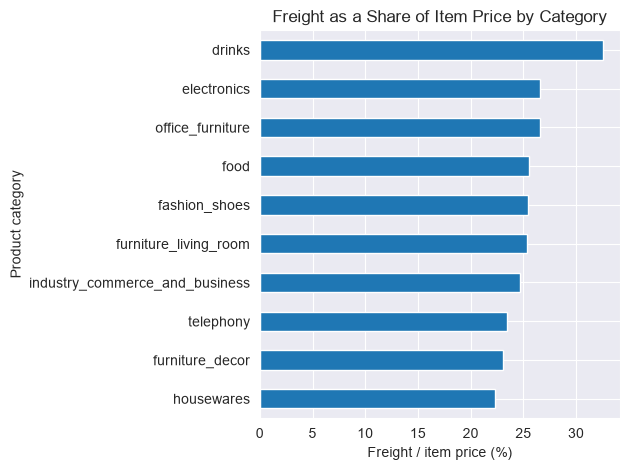

In [24]:
freight_by_category = (
    items_products.groupby(
        "product_category_name_english",
        dropna=False
    )
    .agg(
        item_count=("order_item_id", "size"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
    )
)

freight_by_category = freight_by_category.query(
    "item_count >= 20"
).copy()

freight_by_category["freight_ratio_pct"] = (
    freight_by_category["total_freight"]
    / freight_by_category["total_price"]
    * 100
)

freight_by_category = freight_by_category.sort_values(
    "freight_ratio_pct",
    ascending=False
)

display(freight_by_category.head(10))

freight_by_category["freight_ratio_pct"].head(10).sort_values().plot(
    kind="barh"
)
plt.title("Freight as a Share of Item Price by Category")
plt.xlabel("Freight / item price (%)")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

## Seller Performance Analysis

This section evaluates seller activity and sales performance.

The analysis focuses on:
- Top sellers by number of items sold.
- Total merchandise sales by seller.
- Seller contribution to business performance.

The objective is to identify the most active
and valuable sellers.

,order_item_id,price
seller_id,,
4869f7a5dfa277a7dca6462dcf3b52b2,104,23578.59
fa1c13f2614d7b5c4749cbc52fecda94,52,18627.85
53243585a1d6dc2643021fd1853d8905,32,17635.86
4a3ca9315b744ce9f8e9374361493884,166,17348.15
da8622b14eb17ae2831f4ac5b9dab84a,138,14270.39
b37c4c02bda3161a7546a4e6d222d5b2,8,13440.00
7c67e1448b00f6e969d365cea6b010ab,95,12773.43
6560211a19b47992c3666cc44a7e94c0,188,11781.00
7a67c85e85bb2ce8582c35f2203ad736,91,11682.09


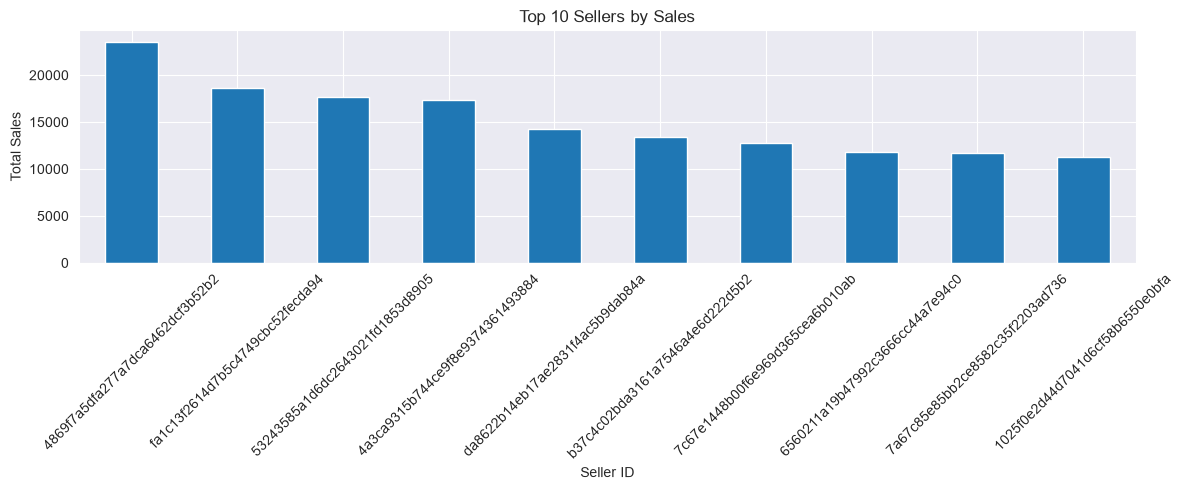

In [25]:
seller_performance = (
    sheets["Order_Items"]
    .groupby("seller_id")
    .agg({
        "order_item_id": "count",
        "price": "sum"
    })
)

seller_performance = seller_performance.sort_values(
    "price", ascending=False
)

display(seller_performance.head(10))

seller_performance["price"].head(10).plot(
    kind="bar", figsize=(12, 5)
)

plt.title("Top 10 Sellers by Sales")
plt.xlabel("Seller ID")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Customer Purchase Time Analysis

This section explores when customers usually place their orders.

The analysis examines order distribution by:
- Day of the week.
- Hour of the day.

The objective is to identify the busiest
periods for customer purchases.

Peak purchase hour: 11:00 (545 orders)


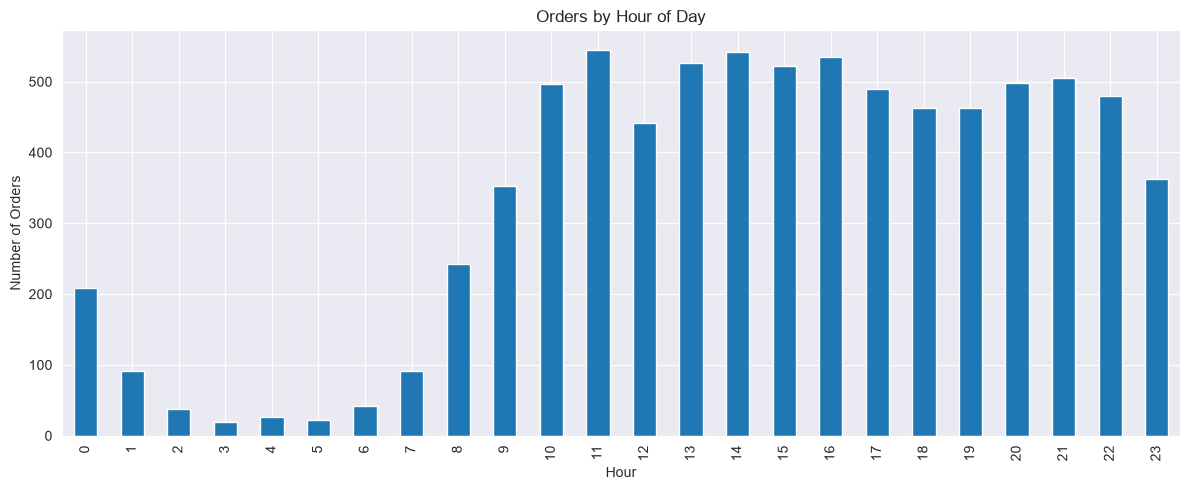

,Orders
purchase_day,
Monday,1297
Tuesday,1256
Wednesday,1269
Thursday,1189
Friday,1189
Saturday,871
Sunday,931


Peak purchase weekday: Monday (1,297 orders)


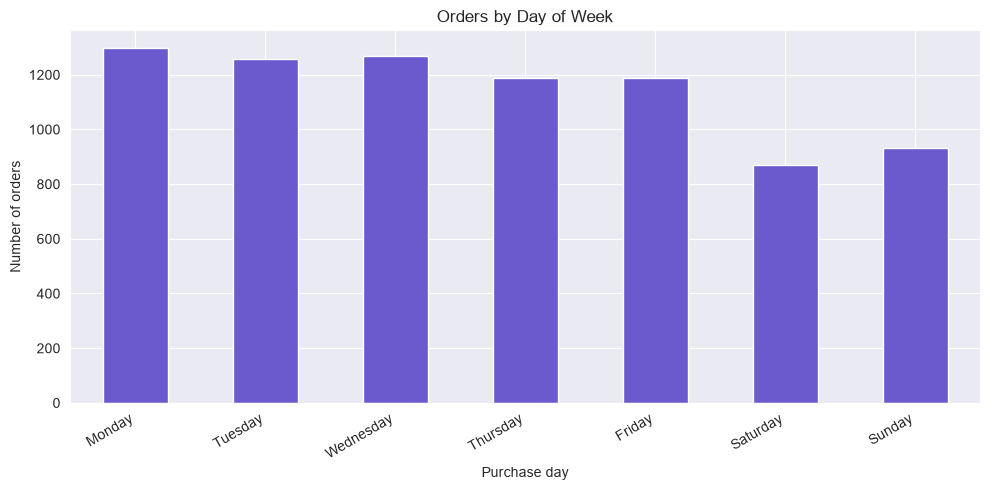

In [26]:
orders = sheets["Orders"].copy()
orders["purchase_hour"] = orders["order_purchase_timestamp"].dt.hour
orders["purchase_day"] = orders["order_purchase_timestamp"].dt.day_name()
hour_counts = orders["purchase_hour"].value_counts().sort_index()
print(f"Peak purchase hour: {hour_counts.idxmax():02d}:00 ({hour_counts.max():,} orders)")
hour_counts.plot(kind="bar", figsize=(12, 5))
plt.title("Orders by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = orders["purchase_day"].value_counts().reindex(weekday_order, fill_value=0)
display(weekday_counts.rename("Orders").to_frame())
print(f"Peak purchase weekday: {weekday_counts.idxmax()} ({weekday_counts.max():,} orders)")
weekday_counts.plot(kind="bar", figsize=(10, 5), color="slateblue")
plt.title("Orders by Day of Week")
plt.xlabel("Purchase day")
plt.ylabel("Number of orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** Monday had 1,297 purchases; Saturday had 871 and Sunday 931. The peak purchase hour was 11:00, with 545 orders.

# Key Findings

1. **Order performance:** 7,746 of 8,002 orders were delivered (96.8%).
2. **Monthly order volume:** November 2017 had the highest order count (609); August 2018 is a partial month.
3. **Product performance:** Watches & Gifts generated the highest total item value (R$105,564.80), not profit.
4. **Payment behavior:** Credit card payments had the highest total payment value (R$998,943.13).
5. **Customer satisfaction:** Average review score was 4.08/5; score 5 appeared in 4,600 of 7,986 reviews (57.6%).
6. **Delivery:** 669 of 7,745 eligible orders were late (8.64%). Median delivery time was 10.21 days; the maximum was 187.20 days and should be investigated.
7. **Repeat purchasing:** 23 of 7,979 unique customers had multiple orders (0.29%) in this approximately 8% sample. This does not establish population-wide retention.
8. **Geography:** São Paulo had the most orders (3,369 of 8,002). The added state delay table uses eligible delivered orders as its denominator.

These are descriptive findings from this sample and do not establish causes.

# Business Recommendations

1. **Delivery improvement:** Investigate groups with higher eligible late-delivery rates; 669 of 7,745 eligible orders were late (8.64%).
2. **Product management:** Use category item value and item counts to guide demand reviews; these are not profit measures.
3. **Shipping optimization:** Review categories with higher freight-to-price ratios, considering their item counts.
4. **Customer satisfaction:** Monitor latest review scores alongside delivery time and investigate low-score cases.
5. **Seller management:** Monitor performance across the seller base; the top 10 sellers contribute about 14.3% of item sales.
6. **Customer retention:** Only 23 of 7,979 customers (0.29%) repeated in this approximately 8% sample. Validate with the full dataset before concluding retention is low or launching a loyalty intervention.
7. **Demand planning:** Use monthly orders and sales as descriptive inputs, accounting for the partial August 2018 month.

# Analysis Limitations

- The workbook is approximately an 8% sample according to the project brief; counts and rates may not represent the full population.
- Monetary values are recorded in BRL and describe merchandise value, not profit. Freight and payment values are separate measures.
- Delivery rates use only orders with the timestamps required for each calculation; denominators are displayed.
- The longest recorded delivery duration is about 187 days. Investigate this extreme value for an exceptional delivery or data issue.
- There are 49 orders with multiple review records. This analysis uses each order's latest review to avoid fractional mean scores; the choice should be stated when interpreting the plot.
- Category and seller late rates use item rows, so an order can appear in multiple groups. Monthly rates count each eligible order once.
- Order-sequence checks are data-quality flags that need source review.
- Descriptive comparisons do not prove causation. Complete inventory and operating-cost data are unavailable.

# Final Conclusion

This exploratory analysis describes sales, customer behavior, reviews, and delivery performance in the supplied Olist sample. Most delivered orders arrived before the estimate, repeat purchasing was rare in this sample, and the order-level state and monthly tables provide leads for follow-up.

These results apply to the sample and definitions used. Validate findings on the full dataset and investigate data-quality outliers before making operational decisions.